# UNM ds003490 - Enfoque A: representación funcional en frecuencia

Este cuaderno construye y caracteriza el **Enfoque A** sobre el dominio espectral de
**4 a 13 Hz**. Parte exclusivamente de las épocas válidas producidas por el cuaderno 01
(48 sujetos: 24 HC y 24 PD_OFF) y mantiene los **10 canales** seleccionados. Sus salidas
(`enfoque_A_sujeto_dataset.npz` y `enfoque_A_dataset.npz`) son la entrada del cuaderno
de modelado.

El flujo implementado es:

1. cálculo de PSD relativa logarítmica por época y canal;
2. selección de la complejidad B-spline mediante GCV;
3. análisis de sensibilidad **B-spline vs P-spline** para justificar la familia de base;
4. caracterización de las curvas funcionales por sujeto y canal;
5. construcción de A1 (una representación por sujeto) y A2 (una representación por época);
6. transformación de Cholesky para preservar la geometría funcional y figura de
   reconstrucción.

La P-spline se mantiene únicamente como **análisis de sensibilidad**. Los archivos que
alimentan el modelado utilizan la representación B-spline seleccionada por GCV. La FPCA
mostrada en la figura de reconstrucción es ilustrativa; en el modelado se ajusta dentro de
cada partición de entrenamiento para evitar fuga de información.

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# ============================================================================
# ENFOQUE A -- Caracterizacion funcional (dominio frecuencia)
# Autocontenido: lee las epocas de 10 canales del preprocesamiento, calcula la
# PSD relativa log, la suaviza con B-spline (banda 4-13 Hz) y caracteriza la
# senal funcional. No entrena ningun modelo.
# ============================================================================
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.integrate import simpson
from scipy import linalg
from sklearn.preprocessing import SplineTransformer
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# -- Rutas (mismas del preprocesamiento) --
FINAL_ROOT = Path('/content/drive/MyDrive/tesis_parkinson/resultados')
PREPROC_DIR = FINAL_ROOT / '01_preprocesamiento'
EPOCHS_DIR  = PREPROC_DIR / 'preprocessed_epochs'
MANIFEST    = PREPROC_DIR / 'epochs_manifest.csv'
OUT_DIR     = FINAL_ROOT / '02A_enfoque_A'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT_DIR / 'figuras'
FIG_TESIS_DIR = FIG_DIR / 'tesis'
FIG_AUX_DIR = FIG_DIR / 'auxiliares'
for _d in (FIG_DIR, FIG_TESIS_DIR, FIG_AUX_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# -- Parametros del Enfoque A (dominio frecuencia) --
PSD_FMIN, PSD_FMAX   = 1.0, 40.0      # Welch (rango de calculo)
NORM_FMAX            = 30.0           # potencia total para PSD relativa (Jaramillo)
# Banda theta+alfa: concentra el biomarcador (enlentecimiento del alfa) y mantiene
# la representacion compacta (menor dimension). El panorama del espectro completo
# se muestra en la caracterizacion cruda del cuaderno 01.
BAND_FMIN, BAND_FMAX = 4.0, 13.0      # banda funcional (theta + alfa)
WELCH_SEC, WELCH_OVL = 2.0, 0.5
BSPLINE_DEGREE = 3
BSPLINE_RIDGE  = 1e-6
# El numero de nudos NO se fija aqui: lo elige el GCV (celda de seleccion).
CHANNEL = 'Pz'                        # canal para la figura de caracterizacion
MIN_EPOCHS = 6
print(f'Enfoque A | banda {BAND_FMIN}-{BAND_FMAX} Hz | 10 canales | complejidad por GCV')


Enfoque A | banda 4.0-13.0 Hz | 10 canales | complejidad por GCV


## 1. Carga de la cohorte y construcción de las curvas espectrales

Se calcula una única vez la PSD relativa logarítmica por época y canal. La potencia
total de referencia se integra entre 1 y 30 Hz y la representación funcional se
restringe posteriormente a 4-13 Hz.


In [13]:
# -- Cargar manifest, asignar etiqueta y filtrar CTL vs PD_OFF --
man = pd.read_csv(MANIFEST)
man['error'] = man['error'].fillna('').astype(str)
man = man[(man['error'] == '') & (man['n_epocas_conservadas'] >= MIN_EPOCHS)]
man = man[man['condition'].isin(['CTL', 'PD_OFF'])].copy()
man['label'] = man['condition'].map({'CTL': 0, 'PD_OFF': 1})
print(f"Sujetos: {len(man)} "
      f"(HC={int((man.label == 0).sum())}, PD_OFF={int((man.label == 1).sum())})")


def psd_rel_log_epochs(data_uv, sfreq):
    """PSD relativa log por epoca, restringida a la banda funcional (4-13 Hz)."""
    nps = min(int(sfreq * WELCH_SEC), data_uv.shape[-1])
    nov = int(nps * WELCH_OVL)
    f, psd = welch(data_uv, fs=sfreq, nperseg=nps, noverlap=nov, axis=-1)
    nm = (f >= PSD_FMIN) & (f <= NORM_FMAX)
    df = f[1] - f[0]
    tot = simpson(psd[..., nm], dx=df, axis=-1)
    tot = np.where(tot < 1e-20, 1e-20, tot)
    rel_log = np.log10(psd / tot[..., None] + 1e-20)
    bm = (f >= BAND_FMIN) & (f <= BAND_FMAX)
    return rel_log[..., bm], f[bm]


# Se carga la PSD relativa log por epoca de cada sujeto UNA sola vez.
# Sirve para el GCV (siguiente celda) y para construir las curvas.
per_subj = []
freqs_band = None
ch_ref = None
for _, r in man.iterrows():
    data = np.load(r['file']).astype(np.float64)
    ch_names = r['ch_names'].split(',')
    rel_log, fb = psd_rel_log_epochs(data, float(r['sfreq']))     # (n_ep, n_ch, nf)
    if freqs_band is None:
        freqs_band, ch_ref = fb, ch_names
    # Conservar metadatos mínimos del sujeto para las figuras de trazabilidad.
    subject_id = str(r.get('subject_id', r.get('subject', ''))).strip()
    if not subject_id:
        import re
        match = re.search(r'(sub-[A-Za-z0-9]+)', str(r['file']))
        subject_id = match.group(1) if match else f'sujeto-{len(per_subj):02d}'
    per_subj.append({
        'label': int(r['label']),
        'rel_log': rel_log,
        'ch_names': ch_names,
        'subject_id': subject_id,
        'n_ep': int(rel_log.shape[0]),
    })

print(f"Cargados {len(per_subj)} sujetos | banda {freqs_band[0]:.0f}-{freqs_band[-1]:.0f} Hz "
      f"({len(freqs_band)} puntos) | canales {ch_ref}")


Sujetos: 48 (HC=24, PD_OFF=24)
Cargados 48 sujetos | banda 4-13 Hz (19 puntos) | canales ['C3', 'Cz', 'C4', 'P7', 'P8', 'P3', 'Pz', 'P4', 'O1', 'O2']


## 2. Selección de la complejidad B-spline mediante GCV

El número de nudos se selecciona mediante GCV sobre curvas época-canal. Esta etapa
no utiliza etiquetas de grupo ni desempeño de clasificación. El valor seleccionado se
usa después para construir las representaciones funcionales B-spline del Enfoque A.

k optimo por GCV: 9 nudos (11 bases)


,k,n_bases,gcv_medio,gcv_std
0,4,6,0.09743,0.05642
1,5,7,0.09170,0.05434
2,6,8,0.08926,0.05428
3,7,9,0.08561,0.05375
4,8,10,0.08845,0.06113
5,9,11,0.08533,0.06318
6,10,12,0.09033,0.06944
7,12,14,0.10691,0.09585
8,15,17,0.21194,0.32528


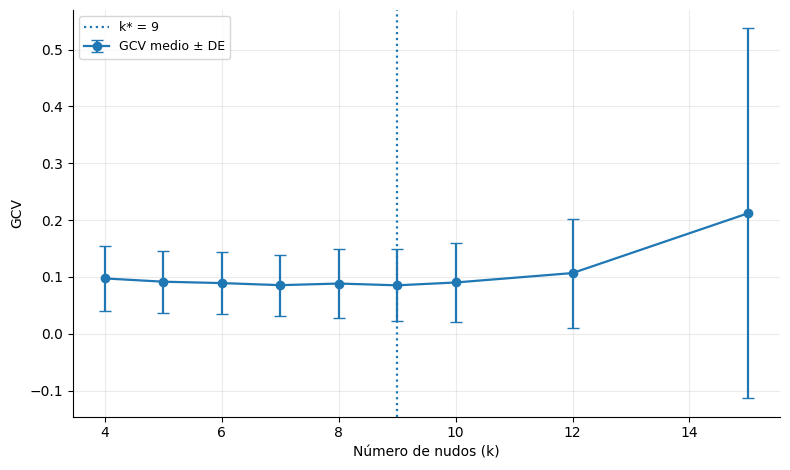

Figura guardada: /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/figuras/tesis/gcv_enfoque_A.png


In [14]:
# -- SELECCION DEL NUMERO DE NUDOS POR GCV --
#    Sobre una muestra de las curvas espectrales epoca-canal (el objeto que el
#    modelo realmente ajusta), se prueba un rango de k y se elige el que minimiza
#    el GCV promedio. GCV = MSE / (1 - df/n)^2, con df = traza de la matriz hat.
#    El k elegido (K_OPT) se usa en todo el resto del cuaderno.
K_RANGE = [4, 5, 6, 7, 8, 9, 10, 12, 15]
GCV_SAMPLE = 300                       # curvas epoca-canal para promediar el GCV
GCV_RNG = np.random.default_rng(RANDOM_STATE)


def _bspline_gcv(x, y, n_knots, degree=BSPLINE_DEGREE, ridge=BSPLINE_RIDGE):
    xc = x.reshape(-1, 1)
    B = SplineTransformer(n_knots=n_knots, degree=degree, include_bias=True).fit_transform(xc)
    n, nb = B.shape
    if nb >= n:
        return np.inf                  # base saturada
    P = B.T @ B + ridge * np.eye(nb)
    H = B @ linalg.pinv(P) @ B.T        # matriz hat
    yh = H @ y
    mse = ((y - yh) ** 2).mean()
    df = np.trace(H)                    # grados de libertad efectivos
    den = (1.0 - df / n) ** 2
    return np.inf if den < 1e-10 else mse / den


# muestra de curvas epoca-canal (todas juntas)
all_curves = np.concatenate([s['rel_log'].reshape(-1, len(freqs_band)) for s in per_subj], axis=0)
idx = GCV_RNG.choice(len(all_curves), size=min(GCV_SAMPLE, len(all_curves)), replace=False)
sample = all_curves[idx]

rows = []
for k in K_RANGE:
    gcvs = [_bspline_gcv(freqs_band, sample[i], k) for i in range(len(sample))]
    gcvs = [g for g in gcvs if np.isfinite(g)]
    if gcvs:
        rows.append({'k': k, 'n_bases': k + BSPLINE_DEGREE - 1,
                     'gcv_medio': float(np.mean(gcvs)), 'gcv_std': float(np.std(gcvs))})
gcv_tab = pd.DataFrame(rows)
K_OPT = int(gcv_tab.loc[gcv_tab['gcv_medio'].idxmin(), 'k'])
print(f"k optimo por GCV: {K_OPT} nudos ({K_OPT + BSPLINE_DEGREE - 1} bases)")
display(gcv_tab.round(5))
gcv_tab.to_csv(OUT_DIR / 'gcv_enfoque_A.csv', index=False)

# Figura de GCV del Enfoque A (sin título interno).
fig, ax = plt.subplots(figsize=(8.0, 4.8))
ax.errorbar(
    gcv_tab['k'], gcv_tab['gcv_medio'], yerr=gcv_tab['gcv_std'],
    marker='o', lw=1.6, capsize=4, label='GCV medio ± DE',
)
ax.axvline(K_OPT, ls=':', lw=1.6, label=f'k* = {K_OPT}')
ax.set_xlabel('Número de nudos (k)')
ax.set_ylabel('GCV')
ax.legend(fontsize=9, frameon=True)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig_gcv = FIG_TESIS_DIR / 'gcv_enfoque_A.png'
fig.savefig(fig_gcv, dpi=220, bbox_inches='tight')
plt.show()
print('Figura guardada:', fig_gcv)


## 3. Análisis de sensibilidad: B-spline frente a P-spline

Se compara la B-spline utilizada en el Enfoque A con una P-spline construida sobre
una base rica de **17 funciones** y penalización de diferencias de segundo orden. El
parámetro de penalización se selecciona mediante GCV.

Esta comparación es exclusivamente un análisis de sensibilidad de la representación.
La P-spline **no sustituye** la representación B-spline que alimenta los modelos.

P-spline A | 17 funciones base | lambda*=2.154e-02 | df efectivos=11.45 | GCV=0.058617
Tabla: /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/comparacion_bspline_pspline_A.csv


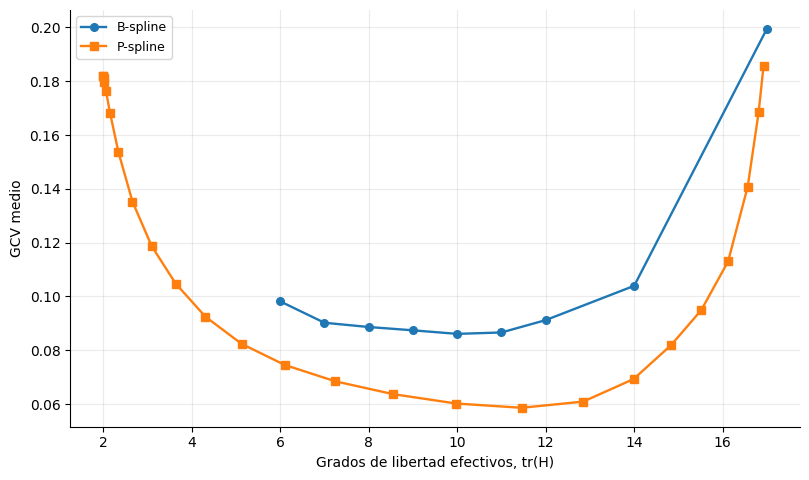

Figura guardada: /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/figuras/tesis/comparacion_bspline_pspline_A.png


In [15]:
# ============================================================================
# ANÁLISIS DE SENSIBILIDAD B-SPLINE VS P-SPLINE
# ============================================================================
N_RICH_A = 15                 # 15 nudos -> 17 funciones base cúbicas
PEN_ORDER = 2
PS_RIDGE = 1e-8
LAM_RANGE = np.logspace(-5, 5, 25)
PS_GCV_SAMPLE = 400


def _difference_penalty(n_basis: int, order: int = PEN_ORDER) -> np.ndarray:
    D = np.eye(n_basis)
    for _ in range(order):
        D = np.diff(D, axis=0)
    return D.T @ D


def _hat_stats(Y: np.ndarray, B: np.ndarray, penalty: np.ndarray,
               lam: float, ridge: float) -> tuple[float, float]:
    n, nb = B.shape
    system = B.T @ B + lam * penalty + ridge * np.eye(nb)
    inv_system = linalg.pinv(system)
    H = B @ inv_system @ B.T
    df_eff = float(np.trace(H))
    Yhat = Y @ H.T
    mse = ((Y - Yhat) ** 2).mean(axis=1)
    denominator = (1.0 - df_eff / n) ** 2
    return df_eff, float(np.mean(mse / denominator))


# Muestra común para comparar ambos métodos bajo los mismos datos.
_rng_ps = np.random.default_rng(RANDOM_STATE)
_idx_ps = _rng_ps.choice(
    len(all_curves), size=min(PS_GCV_SAMPLE, len(all_curves)), replace=False,
)
_sample_ps = all_curves[_idx_ps]

comparison_rows = []

# B-spline: complejidad controlada por número de nudos.
for k in K_RANGE:
    Bk = SplineTransformer(
        n_knots=k, degree=BSPLINE_DEGREE, include_bias=True
    ).fit_transform(freqs_band.reshape(-1, 1))
    if Bk.shape[1] >= Bk.shape[0]:
        continue
    df_eff, gcv_mean = _hat_stats(
        _sample_ps, Bk, np.zeros((Bk.shape[1], Bk.shape[1])), 0.0, BSPLINE_RIDGE,
    )
    comparison_rows.append({
        'metodo': 'B-spline', 'parametro': f'k={k}',
        'df_efectivos': df_eff, 'gcv_medio': gcv_mean,
    })

# P-spline: base rica fija + penalización de rugosidad.
_sp_ps = SplineTransformer(
    n_knots=N_RICH_A, degree=BSPLINE_DEGREE, include_bias=True
)
_B_ps = _sp_ps.fit_transform(freqs_band.reshape(-1, 1))
assert _B_ps.shape[1] == 17, f'Se esperaban 17 funciones P-spline, se obtuvieron {_B_ps.shape[1]}'
_P_ps = _difference_penalty(_B_ps.shape[1])

for lam in LAM_RANGE:
    df_eff, gcv_mean = _hat_stats(_sample_ps, _B_ps, _P_ps, float(lam), PS_RIDGE)
    comparison_rows.append({
        'metodo': 'P-spline', 'parametro': f'lambda={lam:.6g}',
        'df_efectivos': df_eff, 'gcv_medio': gcv_mean,
    })

comparison_basis = pd.DataFrame(comparison_rows)
ps_only = comparison_basis[comparison_basis['metodo'] == 'P-spline'].copy()
ps_best_idx = ps_only['gcv_medio'].idxmin()
LAM_OPT_A = float(
    ps_only.loc[ps_best_idx, 'parametro'].split('=')[1]
)
DF_OPT_PS = float(ps_only.loc[ps_best_idx, 'df_efectivos'])
GCV_OPT_PS = float(ps_only.loc[ps_best_idx, 'gcv_medio'])

comparison_csv = OUT_DIR / 'comparacion_bspline_pspline_A.csv'
comparison_basis.to_csv(comparison_csv, index=False)

print(
    f'P-spline A | 17 funciones base | lambda*={LAM_OPT_A:.3e} | '
    f'df efectivos={DF_OPT_PS:.2f} | GCV={GCV_OPT_PS:.6f}'
)
print('Tabla:', comparison_csv)

# Figura de comparación sobre grados de libertad efectivos.
fig, ax = plt.subplots(figsize=(8.2, 4.9))
for method, marker in [('B-spline', 'o'), ('P-spline', 's')]:
    sub = comparison_basis[comparison_basis['metodo'] == method].sort_values('df_efectivos')
    ax.plot(
        sub['df_efectivos'], sub['gcv_medio'],
        marker=marker, lw=1.7, ms=5.5, label=method,
    )
ax.set_xlabel('Grados de libertad efectivos, tr(H)')
ax.set_ylabel('GCV medio')
ax.legend(fontsize=9, frameon=True)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig_bspline_pspline = FIG_TESIS_DIR / 'comparacion_bspline_pspline_A.png'
fig.savefig(fig_bspline_pspline, dpi=220, bbox_inches='tight')
plt.show()
print('Figura guardada:', fig_bspline_pspline)


## 4. Construcción de curvas funcionales por sujeto y canal

Con la complejidad B-spline seleccionada se construyen, para caracterización, las
curvas promedio por sujeto y canal. A1 y A2 se construyen más adelante a partir de
la misma definición espectral.


In [16]:
# -- Construir curvas por sujeto-canal usando el k elegido por GCV (K_OPT) --
def smooth_bspline(x, y, n_knots, degree=BSPLINE_DEGREE, ridge=BSPLINE_RIDGE):
    xc = np.asarray(x).reshape(-1, 1)
    B = SplineTransformer(n_knots=n_knots, degree=degree, include_bias=True).fit_transform(xc)
    P = B.T @ B + ridge * np.eye(B.shape[1])
    coef = y @ B @ linalg.pinv(P)
    return coef @ B.T, coef


# curves_all -> por SUJETO y CANAL (n_subj, n_ch, nf): cruda (media de epocas) y funcional.
# epoch_Pz   -> por EPOCA en Pz (para la tabla de medias/DE).
# verif      -> todas las curvas epoca-canal (para la verificacion).
curves_all = {0: {'crude': [], 'func': []}, 1: {'crude': [], 'func': []}}
epoch_Pz = {0: {'raw': [], 'fit': []}, 1: {'raw': [], 'fit': []}}
verif_raw, verif_fit = [], []
pz_ok = CHANNEL in ch_ref
for s in per_subj:
    rel_log = s['rel_log']
    lab = s['label']
    ne, nc, nf = rel_log.shape

    subj_crude = rel_log.mean(0)                                  # (n_ch, nf)
    subj_func, _ = smooth_bspline(freqs_band, subj_crude, K_OPT)
    curves_all[lab]['crude'].append(subj_crude)
    curves_all[lab]['func'].append(subj_func)

    if pz_ok:
        ci = ch_ref.index(CHANNEL)
        raw_ep = rel_log[:, ci, :]
        fit_ep, _ = smooth_bspline(freqs_band, raw_ep, K_OPT)
        epoch_Pz[lab]['raw'].append(raw_ep)
        epoch_Pz[lab]['fit'].append(fit_ep)

    raw_flat = rel_log.reshape(ne * nc, nf)
    fit_flat, _ = smooth_bspline(freqs_band, raw_flat, K_OPT)
    verif_raw.append(raw_flat)
    verif_fit.append(fit_flat)

for lab in (0, 1):
    curves_all[lab]['crude'] = np.stack(curves_all[lab]['crude'])
    curves_all[lab]['func'] = np.stack(curves_all[lab]['func'])
    epoch_Pz[lab]['raw'] = np.concatenate(epoch_Pz[lab]['raw'], 0)
    epoch_Pz[lab]['fit'] = np.concatenate(epoch_Pz[lab]['fit'], 0)
verif_raw = np.concatenate(verif_raw, 0)
verif_fit = np.concatenate(verif_fit, 0)


def group_curves(sel):
    """Promedia sobre los canales en 'sel' (indices): {0:{crude,func}, 1:{...}} (n_subj, nf)."""
    return {lab: {'crude': curves_all[lab]['crude'][:, sel, :].mean(1),
                  'func':  curves_all[lab]['func'][:, sel, :].mean(1)} for lab in (0, 1)}


print(f"Curvas por sujeto-canal (k={K_OPT}): "
      f"HC={curves_all[0]['func'].shape}, PD={curves_all[1]['func'].shape}")


Curvas por sujeto-canal (k=9): HC=(24, 10, 19), PD=(24, 10, 19)


## 5. Figuras de caracterización funcional

La figura principal presenta las curvas funcionales de HC y PD_OFF en la fila superior y la
comparación de medias en la fila inferior. Los títulos indican explícitamente el número de
sujetos y canales. Se generan además figuras auxiliares por región y por canal, de carácter
descriptivo.

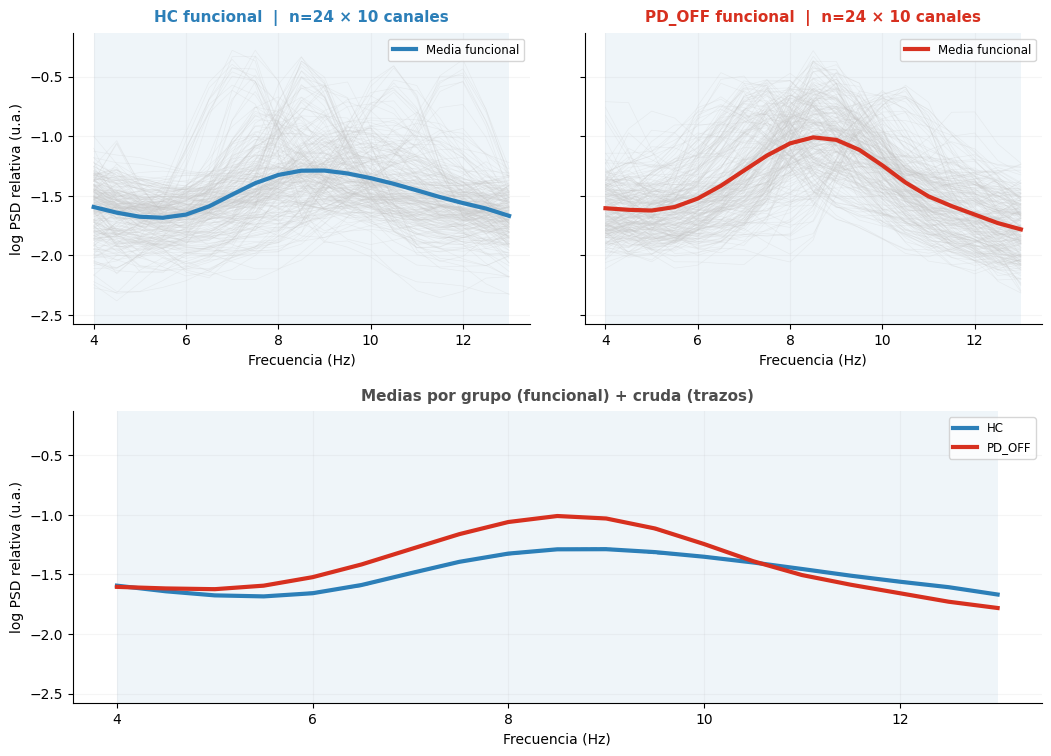

Figura guardada: /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/figuras/tesis/curvas_funcionales_A.png


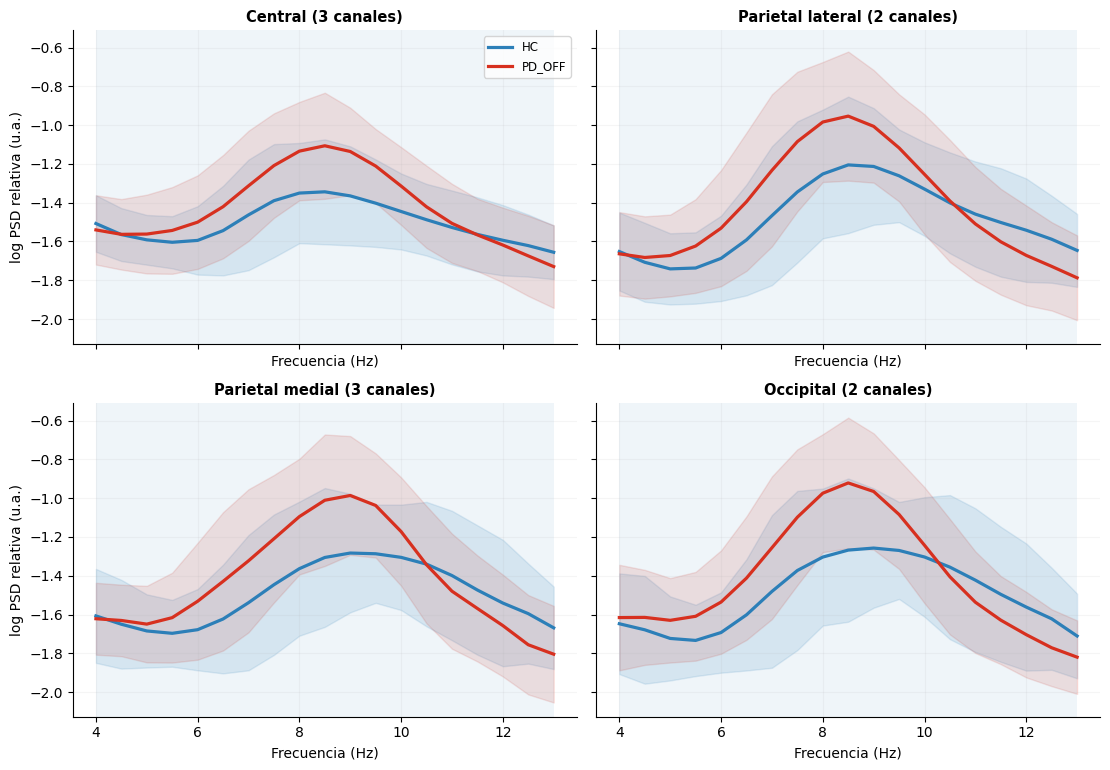

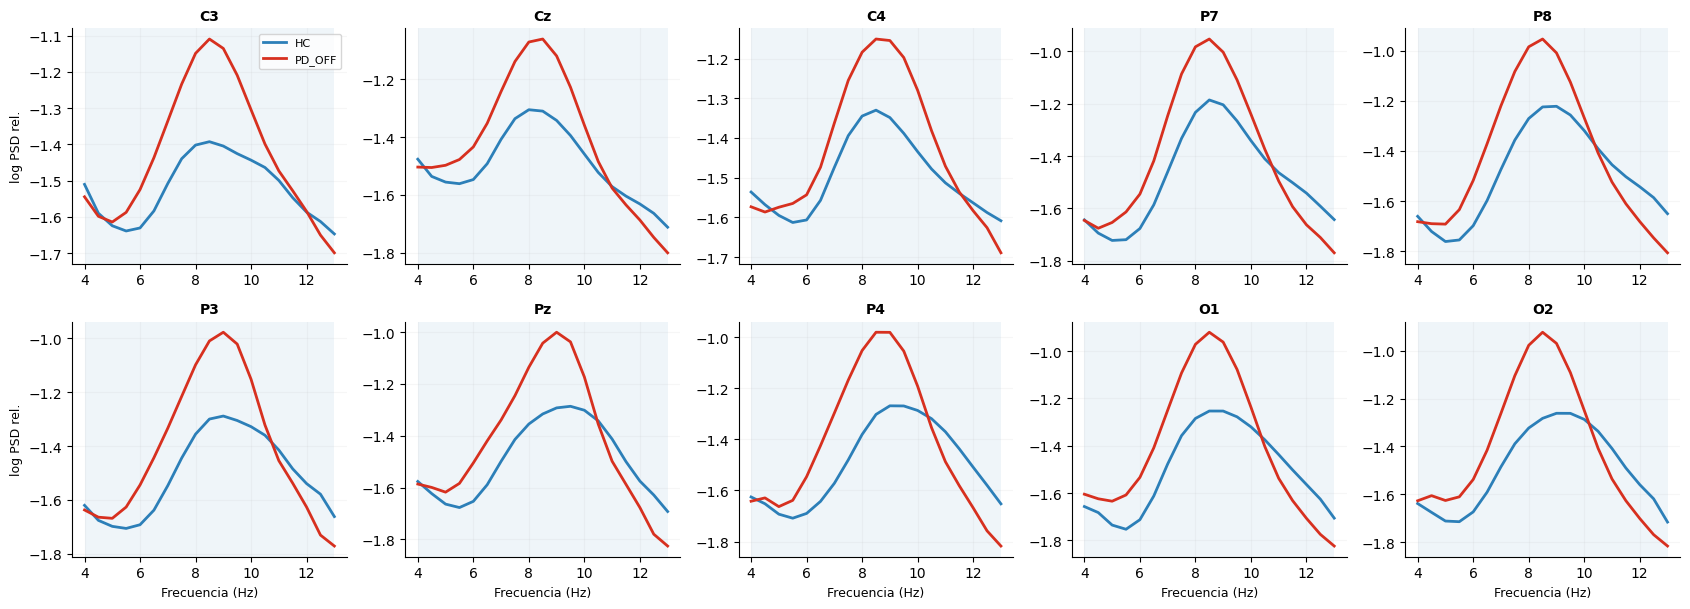

In [17]:
# ============================================================================
# FIGURAS DE CARACTERIZACIÓN FUNCIONAL DEL ENFOQUE A
# ============================================================================
COL = {0: '#2C7FB8', 1: '#D7301F'}
NAME = {0: 'HC', 1: 'PD_OFF'}
ALL_IDX = list(range(len(ch_ref)))
REGIONS_A = {
    'Central': ['C3', 'Cz', 'C4'],
    'Parietal lateral': ['P7', 'P8'],
    'Parietal medial': ['P3', 'Pz', 'P4'],
    'Occipital': ['O1', 'O2'],
}
nfb = len(freqs_band)
n_ch = len(ch_ref)


def _shade(ax):
    ax.axvspan(4, 8, alpha=0.07)
    ax.axvspan(8, 13, alpha=0.07)


gray_c = {
    lab: curves_all[lab]['crude'][:, ALL_IDX, :].reshape(-1, nfb)
    for lab in (0, 1)
}
gray_f = {
    lab: curves_all[lab]['func'][:, ALL_IDX, :].reshape(-1, nfb)
    for lab in (0, 1)
}
nsub = {lab: curves_all[lab]['func'].shape[0] for lab in (0, 1)}
ymin = min(gray_c[lab].min() for lab in (0, 1)) - 0.15
ymax = max(gray_c[lab].max() for lab in (0, 1)) + 0.15


def _draw_group_panel(ax, lab: int) -> None:
    for curve in gray_f[lab]:
        ax.plot(freqs_band, curve, color='0.78', lw=0.45, alpha=0.25)
    ax.plot(
        freqs_band, gray_f[lab].mean(0), color=COL[lab], lw=3.0,
        label='Media funcional',
    )
    _shade(ax)
    ax.set_ylim(ymin, ymax)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.12)
    ax.legend(fontsize=8.5, loc='upper right', frameon=True)
    ax.set_title(
        f'{NAME[lab]} funcional  |  n={nsub[lab]} × {n_ch} canales',
        color=COL[lab], fontsize=11, fontweight='bold', pad=8,
    )


def _draw_mean_panel(ax) -> None:
    for lab in (0, 1):
        ax.plot(
            freqs_band, gray_f[lab].mean(0), color=COL[lab], lw=3.0,
            label=NAME[lab],
        )
        # La curva cruda se deja a trazos como referencia, sin duplicar la leyenda.
        ax.plot(
            freqs_band, gray_c[lab].mean(0), color=COL[lab],
            lw=1.3, ls='--', alpha=0.80,
        )
    _shade(ax)
    ax.set_ylim(ymin, ymax)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.12)
    ax.legend(fontsize=8.5, loc='upper right', frameon=True)
    ax.set_title(
        'Medias por grupo (funcional) + cruda (trazos)',
        color='0.30', fontsize=11, fontweight='bold', pad=8,
    )


# ---------------------------------------------------------------------------
# Curvas funcionales: dos filas.
# ---------------------------------------------------------------------------
fig = plt.figure(figsize=(12.5, 8.7))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.0], hspace=0.30, wspace=0.12)
ax_hc = fig.add_subplot(gs[0, 0])
ax_pd = fig.add_subplot(gs[0, 1], sharey=ax_hc)
ax_mean = fig.add_subplot(gs[1, :], sharey=ax_hc)
_draw_group_panel(ax_hc, 0)
_draw_group_panel(ax_pd, 1)
_draw_mean_panel(ax_mean)
ax_hc.set_ylabel('log PSD relativa (u.a.)')
ax_mean.set_ylabel('log PSD relativa (u.a.)')
ax_hc.set_xlabel('Frecuencia (Hz)')
ax_pd.set_xlabel('Frecuencia (Hz)')
ax_mean.set_xlabel('Frecuencia (Hz)')
plt.setp(ax_pd.get_yticklabels(), visible=False)
fig_curvas = FIG_TESIS_DIR / 'curvas_funcionales_A.png'
fig.savefig(fig_curvas, dpi=220, bbox_inches='tight')
plt.show()
print('Figura guardada:', fig_curvas)

# ---------------------------------------------------------------------------
# Figuras auxiliares por región y por canal.
# ---------------------------------------------------------------------------
zlist = [z for z in REGIONS_A if any(c in ch_ref for c in REGIONS_A[z])]
fig, axes = plt.subplots(2, 2, figsize=(11.2, 7.8), sharex=True, sharey=True)
axes = axes.ravel()
for ax, region in zip(axes, zlist):
    sel = [ch_ref.index(c) for c in REGIONS_A[region] if c in ch_ref]
    gc = group_curves(sel)
    for lab in (0, 1):
        F = gc[lab]['func']
        mean = F.mean(0)
        sd = F.std(0, ddof=1)
        ax.plot(freqs_band, mean, color=COL[lab], lw=2.3, label=NAME[lab])
        ax.fill_between(freqs_band, mean - sd, mean + sd, color=COL[lab], alpha=0.13)
    _shade(ax)
    ax.set_title(f'{region} ({len(sel)} canales)', fontsize=10.5, fontweight='bold')
    ax.set_xlabel('Frecuencia (Hz)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.12)
axes[0].set_ylabel('log PSD relativa (u.a.)')
axes[2].set_ylabel('log PSD relativa (u.a.)')
axes[0].legend(fontsize=8.5, frameon=True)
fig.tight_layout()
fig_aux_regions = FIG_AUX_DIR / 'curvas_funcionales_A_por_region.png'
fig.savefig(fig_aux_regions, dpi=200, bbox_inches='tight')
plt.show()

ncols = 5
nrows = int(np.ceil(len(ch_ref) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.4*ncols, 3.1*nrows), squeeze=False)
for k, ch in enumerate(ch_ref):
    ax = axes[k // ncols][k % ncols]
    for lab in (0, 1):
        F = curves_all[lab]['func'][:, k, :]
        ax.plot(freqs_band, F.mean(0), color=COL[lab], lw=2.0, label=NAME[lab])
    _shade(ax)
    ax.set_title(ch, fontsize=10, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.10)
    if k // ncols == nrows - 1:
        ax.set_xlabel('Frecuencia (Hz)', fontsize=9)
    if k % ncols == 0:
        ax.set_ylabel('log PSD rel.', fontsize=9)
    if k == 0:
        ax.legend(fontsize=8, frameon=True)
for k in range(len(ch_ref), nrows*ncols):
    axes[k // ncols][k % ncols].axis('off')
fig.tight_layout()
fig_aux_channels = FIG_AUX_DIR / 'curvas_funcionales_A_por_canal.png'
fig.savefig(fig_aux_channels, dpi=200, bbox_inches='tight')
plt.show()


## 6. Comparación entre curvas observadas y funcionales

Se cuantifica cuánto modifica el suavizado B-spline la señal espectral mediante medidas
descriptivas de error, correlación y rugosidad. Son verificaciones complementarias que no
se reportan como tablas en la tesis y no intervienen en la clasificación.

In [18]:
# -- Tabla auxiliar 1: medias y desviaciones cruda vs funcional (nivel epoca, Pz, banda alfa) --
#    Objetivo: mostrar que el suavizado PRESERVA la media (media_cruda ~ media_func)
#    pero REDUCE la dispersion puntual (DE_func < DE_cruda). Este contraste indica
#    que el suavizado atenua el ruido sin desplazar el nivel de la senal.
alpha_m = (freqs_band >= 8) & (freqs_band <= 13)
rows = []
for lab in (0, 1):
    R = epoch_Pz[lab]['raw']        # (n_ep, nf) crudas
    S = epoch_Pz[lab]['fit']        # (n_ep, nf) suavizadas
    media_cruda = float(R.mean(0)[alpha_m].mean())      # media puntual (sobre epocas), promedio en alfa
    media_func = float(S.mean(0)[alpha_m].mean())
    de_cruda = float(R.std(0)[alpha_m].mean())          # DE puntual (sobre epocas), promedio en alfa
    de_func = float(S.std(0)[alpha_m].mean())
    rows.append({
        'grupo': NAME[lab], 'n_epocas': len(R),
        'media_cruda': round(media_cruda, 3), 'media_funcional': round(media_func, 3),
        'DE_cruda': round(de_cruda, 3), 'DE_funcional': round(de_func, 3),
        'reduccion_DE_%': round(100 * (de_cruda - de_func) / (de_cruda + 1e-20), 1),
    })
tab_medias = pd.DataFrame(rows)
print(f'MEDIAS y DESVIACIONES cruda vs funcional (nivel epoca, canal {CHANNEL}, banda alfa):')
display(tab_medias)
tab_medias.to_csv(OUT_DIR / 'medias_de_cruda_vs_funcional_A.csv', index=False)

# -- Tabla auxiliar 2: verificacion de reconstruccion (todas las epocas-canales) --
#    Objetivo: cuantificar que cruda y funcional difieren poco pero NO son iguales.
def verif_metrics(R, S):
    rmse = np.sqrt(((R - S) ** 2).mean(1))
    Rc = R - R.mean(1, keepdims=True)
    Sc = S - S.mean(1, keepdims=True)
    corr = (Rc * Sc).sum(1) / (np.sqrt((Rc ** 2).sum(1) * (Sc ** 2).sum(1)) + 1e-20)
    rr = (np.diff(R, n=2, axis=1) ** 2).mean(1)
    rs = (np.diff(S, n=2, axis=1) ** 2).mean(1)
    return rmse, corr, rr, rs


rmse, corr, rr, rs = verif_metrics(verif_raw, verif_fit)
tab_verif = pd.DataFrame([{
    'n_curvas': len(verif_raw),
    'RMSE_medio': round(float(rmse.mean()), 4),
    'correlacion_media': round(float(corr.mean()), 4),
    'rugosidad_cruda': round(float(rr.mean()), 5),
    'rugosidad_funcional': round(float(rs.mean()), 5),
    'reduccion_rugosidad_x': round(float(rr.mean() / (rs.mean() + 1e-20)), 2),
}])
print('\nVERIFICACION cruda vs funcional (reconstruccion, todas las epocas-canales):')
display(tab_verif)
tab_verif.to_csv(OUT_DIR / 'verificacion_cruda_vs_funcional_A.csv', index=False)


MEDIAS y DESVIACIONES cruda vs funcional (nivel epoca, canal Pz, banda alfa):


,grupo,n_epocas,media_cruda,media_funcional,DE_cruda,DE_funcional,reduccion_DE_%
0,HC,382,-1.416,-1.417,0.411,0.393,4.6
1,PD_OFF,347,-1.372,-1.372,0.418,0.395,5.6



VERIFICACION cruda vs funcional (reconstruccion, todas las epocas-canales):


,n_curvas,RMSE_medio,correlacion_media,rugosidad_cruda,rugosidad_funcional,reduccion_rugosidad_x
0,7290,0.1201,0.9357,0.22103,0.06933,3.19


## 7. Construcción de A1/A2, Cholesky y figura de reconstrucción

Se guardan las coordenadas B-spline originales (`X_raw`) y las coordenadas transformadas
por Cholesky (`X_chol`). La transformación de Cholesky no define una curva diferente:
reexpresa la misma función preservando la geometría funcional.

La figura de reconstrucción usa una malla densa para visualizar correctamente la
suavidad de la B-spline. La FPCA de esta figura es únicamente ilustrativa; en el
cuaderno de modelado se ajusta dentro de cada fold.

X_raw (729, 10, 11) | X_chol (729, 10, 11) | epocas=729 (HC=382, PD_OFF=347) | sujetos=48
Dataset guardado: /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/enfoque_A_dataset.npz
[por sujeto] X_raw (48, 10, 11) | X_chol (48, 10, 11) | sujetos=48 (HC=24, PD_OFF=24)
Dataset guardado: /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/enfoque_A_sujeto_dataset.npz


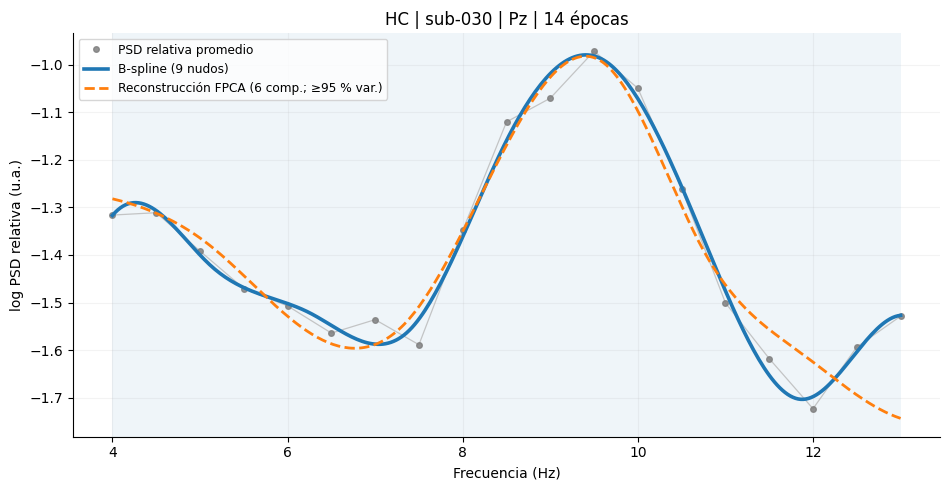

Figura guardada: /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/figuras/tesis/reconstruccion_A_Pz.png
Sujeto ilustrativo: sub-030 | grupo: HC | canal: Pz | épocas: 14
X_raw y X_chol contienen la misma función en sistemas de coordenadas distintos; X_chol no se representa como una curva adicional.
FPCA ilustrativa: 6 componentes retienen al menos 95 % de la varianza en Pz para esta visualización.


In [19]:
# -- CONSTRUCCION de la representacion para el modelo (Enfoque A) --
# Cada EPOCA (no promediada) se convierte en coeficientes B-spline (X_raw) y se
# ortogonaliza con Cholesky de la matriz de Gram (X_chol), para que la distancia
# euclidiana entre vectores corresponda a la distancia funcional (Rossi 2005).
# Se guardan X_raw y X_chol para los cuadernos de modelos. La FPCA NO se guarda
# global: se ajusta DENTRO de cada fold en el modelo, para evitar fuga de datos.
# Aqui solo se ILUSTRA su reconstruccion.
from sklearn.decomposition import PCA

# Base B-spline en la grilla de frecuencias (coeficientes y matriz de Gram)
_sp = SplineTransformer(n_knots=K_OPT, degree=BSPLINE_DEGREE, include_bias=True)
_Bgrid = _sp.fit_transform(freqs_band.reshape(-1, 1))          # (n_freq, n_coef)

# Gram sobre una grilla densa, integrado con Simpson (mismo criterio que Enfoque B).
_freqs_gram = np.linspace(BAND_FMIN, BAND_FMAX, 1001)
_Bgram = _sp.transform(_freqs_gram.reshape(-1, 1))
_products = _Bgram[:, :, None] * _Bgram[:, None, :]
_G = simpson(_products, x=_freqs_gram, axis=0)
_G = 0.5 * (_G + _G.T)
_L = np.linalg.cholesky(_G)                                    # G = L L^T
_Pmat = _Bgrid.T @ _Bgrid + BSPLINE_RIDGE * np.eye(_Bgrid.shape[1])


def coefs_bspline(y):
    """Coeficientes B-spline por minimos cuadrados regularizados. y: (n, n_freq)."""
    return y @ _Bgrid @ linalg.pinv(_Pmat)                     # (n, n_coef)


n_ch = len(ch_ref)
X_raw_list, y_list, groups_list = [], [], []
for si, s in enumerate(per_subj):
    rel = s['rel_log']                                         # (n_ep, n_ch, n_freq)
    ne = rel.shape[0]
    coef = coefs_bspline(rel.reshape(ne * n_ch, rel.shape[-1]))
    X_raw_list.append(coef.reshape(ne, n_ch, -1))
    y_list.append(np.full(ne, s['label']))
    groups_list.append(np.full(ne, si))
X_raw = np.concatenate(X_raw_list, 0)                          # (N_ep, n_ch, n_coef)
y = np.concatenate(y_list, 0)
groups = np.concatenate(groups_list, 0)
X_chol = X_raw @ _L                                            # (N_ep, n_ch, n_coef)
print(f"X_raw {X_raw.shape} | X_chol {X_chol.shape} | epocas={len(y)} "
      f"(HC={int((y == 0).sum())}, PD_OFF={int((y == 1).sum())}) | sujetos={len(per_subj)}")

# Guardar dataset (X_raw, X_chol) + metadatos. La FPCA va en el modelo (dentro del fold).
np.savez_compressed(OUT_DIR / 'enfoque_A_dataset.npz',
                    X_raw=X_raw, X_chol=X_chol, y=y, groups=groups,
                    channels=np.array(ch_ref), freqs=freqs_band,
                    k_opt=K_OPT, band=np.array([BAND_FMIN, BAND_FMAX]))
print('Dataset guardado:', OUT_DIR / 'enfoque_A_dataset.npz')

# -- Dataset POR SUJETO (espectro promedio crudo -> B-spline -> Cholesky) --
# Estrategia A1: una representacion por sujeto (dominio frecuencia). Se promedia el
# espectro crudo (PSD relativa log) de todas las epocas del sujeto y se suaviza una
# SOLA vez (promediar reduce ruido; el B-spline suaviza la forma resultante). El
# dataset por epoca (arriba) corresponde a la estrategia A2.
Xs_list, ys_list = [], []
for s in per_subj:
    avg_spec = s['rel_log'].mean(axis=0)                       # (n_ch, n_freq) espectro promedio
    Xs_list.append(coefs_bspline(avg_spec))                    # (n_ch, n_coef)
    ys_list.append(s['label'])
X_raw_subj = np.stack(Xs_list, 0)                              # (n_subj, n_ch, n_coef)
y_subj = np.array(ys_list)
groups_subj = np.arange(len(per_subj))
X_chol_subj = X_raw_subj @ _L
print(f"[por sujeto] X_raw {X_raw_subj.shape} | X_chol {X_chol_subj.shape} | "
      f"sujetos={len(y_subj)} (HC={int((y_subj == 0).sum())}, PD_OFF={int((y_subj == 1).sum())})")
np.savez_compressed(OUT_DIR / 'enfoque_A_sujeto_dataset.npz',
                    X_raw=X_raw_subj, X_chol=X_chol_subj, y=y_subj, groups=groups_subj,
                    channels=np.array(ch_ref), freqs=freqs_band,
                    k_opt=K_OPT, band=np.array([BAND_FMIN, BAND_FMAX]))
print('Dataset guardado:', OUT_DIR / 'enfoque_A_sujeto_dataset.npz')

# -- FIGURA FINAL DE TRAZABILIDAD: dato observado -> B-spline -> FPCA --
# X_chol no se dibuja como una curva adicional porque representa la misma función
# B-spline en un sistema de coordenadas distinto.
pz = ch_ref.index(CHANNEL) if CHANNEL in ch_ref else 0
Xpz = X_chol_subj[:, pz, :]
_pca = PCA(n_components=0.95, svd_solver='full').fit(Xpz)
Xpz_rec_chol = _pca.inverse_transform(_pca.transform(Xpz))
Xpz_rec_raw = linalg.solve_triangular(
    _L.T, Xpz_rec_chol.T, lower=False, check_finite=True,
).T


def representative_subject_index() -> int:
    target_subject = 'sub-030'
    for idx, subject in enumerate(per_subj):
        if str(subject.get('subject_id', '')).lower() == target_subject:
            return idx
    curves = np.asarray([
        subject['rel_log'].mean(axis=0)[pz] for subject in per_subj
    ], dtype=float)
    median_curve = np.median(curves, axis=0)
    scale = curves.std(axis=0, ddof=1)
    scale = np.where(scale > 1e-12, scale, 1.0)
    return int(np.argmin(np.linalg.norm((curves - median_curve) / scale, axis=1)))


si = representative_subject_index()
subject = per_subj[si]
subject_group = NAME[int(subject['label'])]

raw_curve = subject['rel_log'].mean(axis=0)[pz]

# Malla densa para visualizar la B-spline como función suave.
fine_freq = np.linspace(BAND_FMIN, BAND_FMAX, 301)
B_fine = _sp.transform(fine_freq.reshape(-1, 1))

bspline_curve = B_fine @ X_raw_subj[si, pz, :]
fpca_curve = B_fine @ Xpz_rec_raw[si]

fig, ax = plt.subplots(figsize=(9.6, 5.0))

# PSD relativa promedio observada.
ax.plot(
    freqs_band,
    raw_curve,
    color='0.72',
    lw=0.9,
    alpha=0.8,
)

ax.plot(
    freqs_band,
    raw_curve,
    'o',
    ms=4,
    color='0.50',
    alpha=0.85,
    label='PSD relativa promedio',
)

# Reconstrucción funcional B-spline.
ax.plot(
    fine_freq,
    bspline_curve,
    lw=2.6,
    label=f'B-spline ({K_OPT} nudos)',
)

# Reconstrucción después de FPCA.
ax.plot(
    fine_freq,
    fpca_curve,
    lw=2.0,
    ls='--',
    label=f'Reconstrucción FPCA ({_pca.n_components_} comp.; ≥95 % var.)',
)

# Bandas theta y alfa.
ax.axvspan(4, 8, alpha=0.07)
ax.axvspan(8, 13, alpha=0.07)

ax.set_xlabel('Frecuencia (Hz)')
ax.set_ylabel('log PSD relativa (u.a.)')

# Identificación del sujeto ilustrativo.
ax.set_title(
    f"{subject_group} | {subject['subject_id']} | "
    f"{CHANNEL} | {subject['n_ep']} épocas"
)

ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.15)

ax.legend(
    fontsize=8.7,
    frameon=True,
    loc='best',
)

fig.tight_layout()

# Figura de reconstrucción (tesis).
fig_reconstruccion = FIG_TESIS_DIR / 'reconstruccion_A_Pz.png'

fig.savefig(
    fig_reconstruccion,
    dpi=220,
    bbox_inches='tight',
)

plt.show()

print('Figura guardada:', fig_reconstruccion)
print(
    'Sujeto ilustrativo:',
    subject['subject_id'],
    '| grupo:', subject_group,
    '| canal:', CHANNEL,
    '| épocas:', subject['n_ep'],
)

print(
    'X_raw y X_chol contienen la misma función en sistemas de coordenadas '
    'distintos; X_chol no se representa como una curva adicional.'
)

print(
    f'FPCA ilustrativa: {_pca.n_components_} componentes retienen al menos '
    f'95 % de la varianza en {CHANNEL} para esta visualización.'
)


### 7.1 Validación numérica de la transformación de Cholesky

Se comprueba que la matriz de Gram sea simétrica y definida positiva (autovalor mínimo > 0),
se reporta su número de condición y se verifica que la distancia funcional calculada con la
matriz de Gram coincida con la distancia euclidiana tras la transformación de Cholesky, para
todos los pares de curvas sujeto-canal observadas. Los resultados se guardan en
`validacion_cholesky_A.csv`.

In [20]:
# ============================================================================
# VALIDACIÓN NUMÉRICA DE LA TRANSFORMACIÓN DE CHOLESKY (ENFOQUE A)
# ============================================================================

def validar_cholesky(G: np.ndarray, L: np.ndarray, coefs: np.ndarray) -> dict:
    """Validación numérica de la transformación de Cholesky.

    G: matriz de Gram (n_coef, n_coef); L: factor de Cholesky (G = L L^T);
    coefs: coeficientes B-spline observados (n_curvas, n_coef).
    Compara, para todos los pares de curvas observadas, la distancia funcional
    delta G delta^T con la distancia euclidiana ||delta L||^2 tras la transformación.
    """
    eig = np.linalg.eigvalsh(G)
    err_fact = float(np.abs(G - L @ L.T).max())
    err_dist = 0.0
    for i in range(coefs.shape[0] - 1):
        d = coefs[i + 1:] - coefs[i]
        via_gram = np.einsum('ij,jk,ik->i', d, G, d)
        via_chol = np.sum((d @ L) ** 2, axis=1)
        err_dist = max(err_dist, float(np.abs(via_gram - via_chol).max()))
    return {
        'dimension_G': f'{G.shape[0]} x {G.shape[1]}',
        'simetrica': bool(np.allclose(G, G.T)),
        'lambda_min': float(eig.min()),
        'cond_G': float(np.linalg.cond(G)),
        'error_max_factorizacion': err_fact,
        'error_max_distancia': err_dist,
        'n_curvas': int(coefs.shape[0]),
    }


_coefs_A = X_raw_subj.reshape(-1, X_raw_subj.shape[-1])      # (48 sujetos x 10 canales, n_coef)
tabla_cholesky_A = pd.DataFrame([{'representacion': 'Enfoque A', **validar_cholesky(_G, _L, _coefs_A)}])
assert tabla_cholesky_A.loc[0, 'lambda_min'] > 0, 'La matriz de Gram no es definida positiva.'
tabla_cholesky_A.to_csv(OUT_DIR / 'validacion_cholesky_A.csv', index=False)
print(tabla_cholesky_A.to_string(index=False))

representacion dimension_G  simetrica  lambda_min      cond_G  error_max_factorizacion  error_max_distancia  n_curvas
     Enfoque A     11 x 11       True    0.000772 1399.215311             1.110223e-16         7.993606e-15       480


## 8. Verificación de la cohorte y de los productos generados

Se comprueba que la cohorte y las dimensiones de A1/A2 sean las esperadas y que existan
los archivos principales que utiliza el cuaderno de modelado.

In [21]:
# ============================================================================
# VERIFICACIÓN DEL ENFOQUE A
# ============================================================================
assert len(per_subj) == 48
assert int((y_subj == 0).sum()) == 24
assert int((y_subj == 1).sum()) == 24
assert X_raw_subj.shape[:2] == (48, 10)
assert X_raw.shape[1] == 10
assert X_raw.shape[0] == 729, f'Se esperaban 729 épocas y se obtuvieron {X_raw.shape[0]}'
assert X_raw_subj.shape[-1] == K_OPT + BSPLINE_DEGREE - 1
assert np.isfinite(X_raw).all() and np.isfinite(X_chol).all()

expected_files = [
    OUT_DIR / 'enfoque_A_dataset.npz',
    OUT_DIR / 'enfoque_A_sujeto_dataset.npz',
    OUT_DIR / 'gcv_enfoque_A.csv',
    OUT_DIR / 'comparacion_bspline_pspline_A.csv',
    FIG_TESIS_DIR / 'comparacion_bspline_pspline_A.png',
    FIG_TESIS_DIR / 'gcv_enfoque_A.png',
    FIG_TESIS_DIR / 'curvas_funcionales_A.png',
    OUT_DIR / 'validacion_cholesky_A.csv',
    FIG_TESIS_DIR / 'reconstruccion_A_Pz.png',
]

print('Cohorte A1:', {'HC': int((y_subj == 0).sum()), 'PD_OFF': int((y_subj == 1).sum())})
print('A1:', X_raw_subj.shape, '| A2:', X_raw.shape)
print('k B-spline:', K_OPT, '| funciones base:', X_raw_subj.shape[-1])
print(f'P-spline: 17 funciones | lambda*={LAM_OPT_A:.3e} | df≈{DF_OPT_PS:.2f}')
print('\nArchivos principales:')
for path in expected_files:
    print(' -', path, 'OK' if path.exists() else 'FALTA')
    assert path.exists(), f'No se generó {path}'
print('\nEnfoque A validado estructuralmente.')


Cohorte A1: {'HC': 24, 'PD_OFF': 24}
A1: (48, 10, 11) | A2: (729, 10, 11)
k B-spline: 9 | funciones base: 11
P-spline: 17 funciones | lambda*=2.154e-02 | df≈11.45

Archivos principales:
 - /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/enfoque_A_dataset.npz OK
 - /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/enfoque_A_sujeto_dataset.npz OK
 - /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/gcv_enfoque_A.csv OK
 - /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/comparacion_bspline_pspline_A.csv OK
 - /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/figuras/tesis/comparacion_bspline_pspline_A.png OK
 - /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/figuras/tesis/gcv_enfoque_A.png OK
 - /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/figuras/tesis/curvas_funcionales_A.png OK
 - /content/drive/MyDrive/tesis_parkinson/resultados/02A_enfoque_A/validacion_cholesky_A.csv OK
 - /co